# OPTICS and HDBSCAN — library lab

Hands-on companion to [README §6](../../README.md#6-optics-and-hdbscan). It uses the ready-made implementations in **scikit-learn** and **SciPy**;
the sister notebook [`optics_from_scratch.ipynb`](optics_from_scratch.ipynb) rebuilds the same algorithm in NumPy.

Part of the [clustering labs](../README.md), one folder per method: [k-means](../01-kmeans/kmeans_lab.ipynb) · [hierarchical](../02-hierarchical/hierarchical_lab.ipynb) · [DBSCAN](../03-dbscan/dbscan_lab.ipynb) · [OPTICS / HDBSCAN](../04-optics-hdbscan/optics_hdbscan_lab.ipynb) · [in practice](../05-in-practice/in_practice_lab.ipynb).

**How to use it**

1. Run the first code cell (imports and helpers). After that, run the labs in order (`Shift + Enter` cell by cell, or
   **Run All**). Labs only reuse things from earlier cells, so top-to-bottom always works.
2. Read the "How to read this" box *after* looking at the output: try to guess first.
3. Change the numbers marked `# <- try changing this` and re-run to build intuition.

**One score used everywhere:** the data in these labs comes with the "true" groups it was generated from, which a real
clustering problem doesn't have. We use them only to *grade* a result with the **adjusted Rand index (ARI)**: 1 = the
clusters match the true groups exactly, 0 = no better than random labels (it can dip slightly below 0).

| Lab | What it shows |
|---|---|
| [9](#lab-9) | the reachability plot, DBSCAN cuts from it, xi and HDBSCAN on mixed densities |
| [Summary](#summary) | one line per lab |

Everything runs offline: the data is generated in the notebook or ships with scikit-learn.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN, HDBSCAN, OPTICS, cluster_optics_dbscan
from sklearn.datasets import make_blobs


np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
SEED = 0


def plot_clusters(ax, X, labels, title, centers=None):
    """Scatter 2-D points coloured by cluster label. Label -1 (noise) is drawn as small grey crosses,
    optional `centers` as black stars."""
    labels = np.asarray(labels)
    noise = labels == -1
    ax.scatter(X[~noise, 0], X[~noise, 1], c=labels[~noise] % 10, cmap="tab10", vmin=0, vmax=9, s=12)
    if noise.any():
        ax.scatter(X[noise, 0], X[noise, 1], c="gray", marker="x", s=14, label="noise")
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="*", s=200, label="centroid")
    ax.set_title(title, fontsize=10); ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")


X_dens, y_dens = make_blobs([300, 300, 100], centers=[[0, 0], [1.5, 0], [8, 6]], cluster_std=[0.25, 0.25, 1.5],
                            random_state=SEED)                   # two dense blobs close together, one sparse blob far away


def density_report(labels):
    """What happened to the three true blobs: did the two dense ones (0, 1) end up in one cluster, and how much of
    the sparse one (2) was called noise?"""
    dense_a, dense_b = [np.bincount(labels[y_dens == g] + 1).argmax() - 1 for g in (0, 1)]   # majority label
    merged = dense_a == dense_b and dense_a != -1
    return labels.max() + 1, merged, np.mean(labels[y_dens == 2] == -1)

<a id="lab-9"></a>

## Lab 9 · OPTICS and HDBSCAN: clusters of different density

**Goal:** OPTICS (README §6) doesn't fix `eps`. It visits the points in an order that always moves to the nearest
not-yet-visited dense region, and records each point's **reachability distance** (roughly, how far it is from the dense
region it was reached from). Plotting reachability in that order gives the **reachability plot**: valleys are clusters,
peaks are the gaps between them. Clusters can then be extracted with the **xi** method (steep drops and rises) or by a
DBSCAN-style horizontal cut at any `eps`, with no refitting. HDBSCAN (README §6.4) builds on the same idea and returns
flat clusters automatically. Same mixed-density data as the DBSCAN notebook's [Lab 8](../03-dbscan/dbscan_lab.ipynb#lab-8) (re-created in the first code cell).

<details>
<summary><b>Core distance and reachability distance (click to expand)</b></summary>

* **Core distance** of point $p$: the distance to its `min_samples`-th nearest neighbour (counting $p$ itself). It is
  the smallest `eps` that would make $p$ a core point.
* **Reachability distance** of $o$ from $p$: $\max\big(\text{core distance}(p),\ d(p, o)\big)$. A point right next to
  $p$ can't look closer than $p$'s core distance, which smooths out random gaps inside dense regions.
* OPTICS repeatedly takes the unvisited point with the **smallest** reachability so far, records it, and lowers its
  unvisited neighbours' reachability values. Points of one dense region are visited one after another with small
  values (a valley); jumping to the next region needs a large value (a peak).
* Cutting the plot at height $\varepsilon$ gives exactly what DBSCAN with that $\varepsilon$ would give (up to the
  odd border point), which is why one OPTICS run contains every DBSCAN answer.

</details>

OPTICS (xi = 0.1)                3 clusters; dense blobs merged: no ; sparse blob called noise:   0%; noise overall   0%
OPTICS (xi = 0.05)               3 clusters; dense blobs merged: no ; sparse blob called noise:  32%; noise overall  36%
OPTICS cut at eps = 0.25         2 clusters; dense blobs merged: no ; sparse blob called noise: 100%; noise overall  15%
OPTICS cut at eps = 1.2          2 clusters; dense blobs merged: yes; sparse blob called noise:  10%; noise overall   1%
HDBSCAN (min_cluster_size = 20)  3 clusters; dense blobs merged: no ; sparse blob called noise:   0%; noise overall   2%
time on 700 points, DBSCAN : 0.001 s
time on 700 points, OPTICS : 0.176 s
time on 700 points, HDBSCAN: 0.003 s


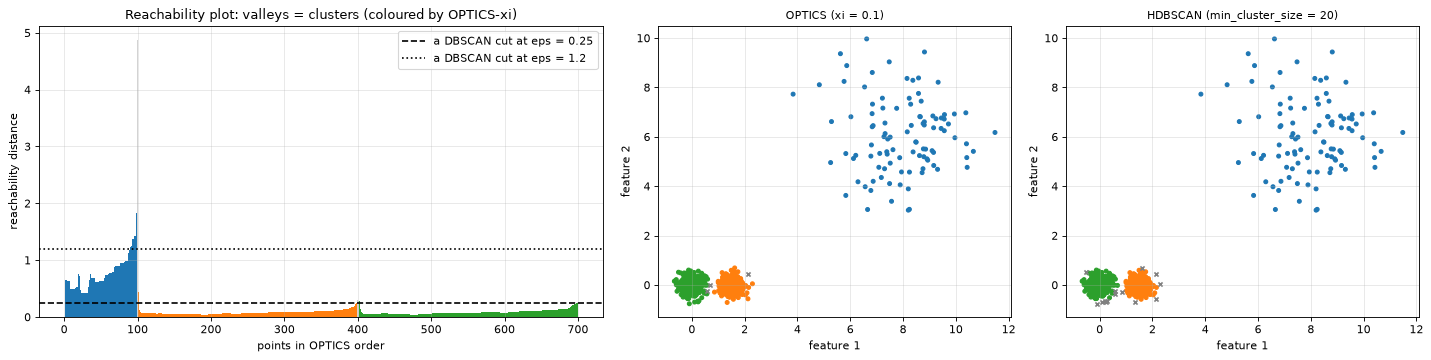

In [2]:
optics = OPTICS(min_samples=10, xi=0.1, min_cluster_size=0.05).fit(X_dens)   # <- try xi = 0.05
reach = optics.reachability_[optics.ordering_]
results = {"OPTICS (xi = 0.1)": optics.labels_,
           "OPTICS (xi = 0.05)": OPTICS(min_samples=10, xi=0.05, min_cluster_size=0.05).fit_predict(X_dens)}
for e in [0.25, 1.2]:
    results[f"OPTICS cut at eps = {e}"] = cluster_optics_dbscan(reachability=optics.reachability_,
                                                                 core_distances=optics.core_distances_,
                                                                 ordering=optics.ordering_, eps=e)
results["HDBSCAN (min_cluster_size = 20)"] = HDBSCAN(min_cluster_size=20, copy=True).fit_predict(X_dens)
for name, labels in results.items():
    found, merged, sparse_noise = density_report(labels)
    print(f"{name:32s} {found} clusters; dense blobs merged: {'yes' if merged else 'no '}; "
          f"sparse blob called noise: {sparse_noise:4.0%}; noise overall {np.mean(labels == -1):4.0%}")
for name, model in [("DBSCAN", DBSCAN(eps=0.25, min_samples=10)), ("OPTICS", OPTICS(min_samples=10)),
                    ("HDBSCAN", HDBSCAN(min_cluster_size=20, copy=True))]:
    start = time.perf_counter(); model.fit(X_dens)
    print(f"time on {len(X_dens)} points, {name:7s}: {time.perf_counter() - start:.3f} s")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), gridspec_kw={"width_ratios": [1.6, 1, 1]})
colors = ["lightgray" if label == -1 else plt.cm.tab10(label % 10) for label in optics.labels_[optics.ordering_]]
axes[0].bar(range(len(reach)), np.where(np.isinf(reach), np.nan, reach), color=colors, width=1.0)
for e, ls in [(0.25, "--"), (1.2, ":")]:
    axes[0].axhline(e, color="black", ls=ls, label=f"a DBSCAN cut at eps = {e}")
axes[0].set_xlabel("points in OPTICS order"); axes[0].set_ylabel("reachability distance")
axes[0].set_title("Reachability plot: valleys = clusters (coloured by OPTICS-xi)"); axes[0].legend()
plot_clusters(axes[1], X_dens, results["OPTICS (xi = 0.1)"], "OPTICS (xi = 0.1)")
plot_clusters(axes[2], X_dens, results["HDBSCAN (min_cluster_size = 20)"], "HDBSCAN (min_cluster_size = 20)")
plt.tight_layout(); plt.show()

> **How to read this**
> * **Reachability plot** (left): the first 100 points (blue) are the sparse blob, with reachability around 0.5–1.8;
>   then two long, low valleys (about 0.05–0.1) are the dense blobs, separated by a small peak near point 400.
> * **Horizontal cuts reproduce DBSCAN:** cutting at 0.25 gives [Lab 8](../03-dbscan/dbscan_lab.ipynb#lab-8)'s eps-0.25 answer (dense blobs separate, sparse
>   blob **100 %** noise); cutting at 1.2 gives the eps-1.2 answer (dense blobs merged, **10 %** noise). One OPTICS
>   run contains every DBSCAN result.
> * **xi extraction** finds clusters by valley depth instead of one height, so it gets all three: with **xi = 0.1**,
>   3 clusters, the dense blobs kept apart, **0 %** noise. It has its own knob: **xi = 0.05** also finds 3 clusters but
>   calls 32 % of the sparse blob noise.
> * **HDBSCAN** finds all three (3 clusters, dense blobs apart, **2 %** noise) with one intuitive setting,
>   `min_cluster_size`.
> * **Speed** on these 700 points (printed above; yours will differ): DBSCAN and HDBSCAN take a few milliseconds,
>   OPTICS takes far longer. In scikit-learn OPTICS is the slowest of the three.

---

<a id="summary"></a>

# Summary — what each lab showed

| Lab | Claim from the README | Verdict |
|---|---|---|
| [9](#lab-9) | OPTICS contains every DBSCAN cut; xi / HDBSCAN handle mixed density | ✔ all three blobs found |